In [1]:
# 1. Cek GPU & Install Library timm
!nvidia-smi
!pip install -q timm


Fri Oct 16 04:29:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# 🌿 Pelatihan Model ConvNeXt-Tiny FLAT Tuned (16 Kelas - 5-Fold Cross Validation)

Notebook terisolasi untuk melatih arsitektur **ConvNeXt-Tiny** secara langsung mengklasifikasikan **16 Kelas Gabungan** (4 Spesies x 4 Tingkat Sangrai) menggunakan skema **Stratified 5-Fold Cross Validation**.

### Konfigurasi Pelatihan (Tuned Standalone):
* **100 Epochs per Fold** dengan **2-Phase Warmup 8 Epoch** (Freeze Backbone lalu Unfreeze dengan Discriminative LR)
* **Patience Early Stopping 15** untuk memastikan konvergensi optimal
* **Augmentasi Terukur (Mild)**: `RandomRotation(15)` dan `ColorJitter(0.05, 0.05)` untuk mempertahankan warna kematangan sangrai
* **Evaluasi Komprehensif**: Akurasi, Precision Macro, Recall Macro, F1 Macro, F1 Weighted, dan Out-of-Fold (OOF) Confusion Matrix


In [2]:
import os
import json
import time
import shutil
import random
import zipfile
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torch.optim.lr_scheduler import CosineAnnealingLR

import timm
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# --- REPRODUCIBILITY SEED ---
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

# --- DEVICE ---
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'[INFO] Running on Device: {device}')
if torch.cuda.is_available():
    print(f'[INFO] GPU: {torch.cuda.get_device_name(0)}')

# --- DIREKTORI DATASET & OUTPUT DI KAGGLE ---
input_base = '/kaggle/input'
work_dir = '/kaggle/working'

# Cari letak Dataset_Split2 di /kaggle/input secara dinamis
TARGET_SPLIT2_DIR = None
for root, dirs, files in os.walk(input_base):
    if 'fold_1' in dirs and 'fold_2' in dirs:
        TARGET_SPLIT2_DIR = root
        break

if TARGET_SPLIT2_DIR is None:
    # Cek jika ada zip file
    for root, dirs, files in os.walk(input_base):
        for f in files:
            if f.endswith('.zip'):
                zp = os.path.join(root, f)
                print(f'Mengekstrak {zp} ke {work_dir}...')
                with zipfile.ZipFile(zp, 'r') as zf:
                    zf.extractall(work_dir)
                break
    for root, dirs, files in os.walk(work_dir):
        if 'fold_1' in dirs and 'fold_2' in dirs:
            TARGET_SPLIT2_DIR = root
            break

MODELS_DIR = os.path.join(work_dir, 'models')
REPORTS_DIR = os.path.join(work_dir, 'reports')
os.makedirs(os.path.join(MODELS_DIR, 'FLAT'), exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

print(f'[INFO] Direktori Dataset: {TARGET_SPLIT2_DIR}')
print(f'[INFO] Simpan Model Ke  : {MODELS_DIR}/FLAT/')
print(f'[INFO] Simpan Report Ke : {REPORTS_DIR}/')


[INFO] Running on Device: cuda
[INFO] GPU: Tesla T4
[INFO] Direktori Dataset: /kaggle/input/datasets/hhnurfathurrachman/coffee-beans-dataset-split2/Dataset_Split2
[INFO] Simpan Model Ke  : /kaggle/working/models/FLAT/
[INFO] Simpan Report Ke : /kaggle/working/reports/


## 2. Dataset PyTorch 16 Kelas & Mild Augmentation (Sama Persis dengan CASCADE)


In [3]:
JENIS_LABELS   = {'arabika': 0, 'ekselsa': 1, 'liberika': 2, 'robusta': 3}
SANGRAI_LABELS = {'dark': 0, 'green': 1, 'light': 2, 'medium': 3}

CLASS_NAMES_16 = [
    f"{j}_{s}" 
    for j in ['Arabika', 'Ekselsa', 'Liberika', 'Robusta']
    for s in ['Dark', 'Green', 'Light', 'Medium']
]

class CoffeeDatasetFlatFolder(Dataset):
    """
    Dataset kustom untuk membaca struktur folder Dataset_Split2/fold_X/train atau val
    berdasarkan 16 kelas gabungan (Jenis x Sangrai).
    """
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.data = []

        for j_folder in sorted(os.listdir(root_dir)):
            j_path = os.path.join(root_dir, j_folder)
            if not os.path.isdir(j_path): continue
            j_idx = JENIS_LABELS.get(j_folder.lower(), -1)
            if j_idx == -1: continue

            for s_folder in sorted(os.listdir(j_path)):
                s_path = os.path.join(j_path, s_folder)
                if not os.path.isdir(s_path): continue
                s_idx = SANGRAI_LABELS.get(s_folder.lower(), -1)
                if s_idx == -1: continue

                lbl_flat = (j_idx * 4) + s_idx
                for img_name in sorted(os.listdir(s_path)):
                    if img_name.lower().endswith(('.jpg', '.jpeg', '.png')):
                        self.data.append((os.path.join(s_path, img_name), lbl_flat))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        path, label = self.data[idx]
        image = Image.open(path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label


def get_transforms(img_size=224):
    train_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        transforms.RandomRotation(degrees=15),
        transforms.ColorJitter(brightness=0.05, contrast=0.05),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    val_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    return train_tf, val_tf


def build_convnext(num_classes=16, drop_rate=0.3):
    model = timm.create_model('convnext_tiny', pretrained=True, num_classes=num_classes, drop_rate=drop_rate)
    in_features = model.head.fc.in_features  # 768
    model.head.fc = nn.Sequential(
        nn.Linear(in_features, 512),
        nn.LayerNorm(512),
        nn.GELU(),
        nn.Dropout(drop_rate),
        nn.Linear(512, num_classes)
    )
    return model


## 3. Engine Pelatihan Single-Fold (100 Epochs, Tuned LR, Patience 15)


In [4]:
def train_kfold_model(
    train_loader,
    val_loader,
    num_classes=16,
    save_name='model.pth',
    label_info='Fold 1',
    target_name=None,
    num_epochs=100,
    warmup_epochs=8,
    patience=15
):
    model = build_convnext(num_classes=num_classes).to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    display_target = target_name if target_name is not None else label_info

    # --- FASE 1: WARMUP (Freeze Backbone) ---
    for p in model.parameters():
        p.requires_grad = False
    for p in model.head.parameters():
        p.requires_grad = True

    optimizer = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=5e-4, weight_decay=1e-2
    )
    scheduler = None

    best_acc = 0.0
    best_val_loss = float('inf')
    patience_counter = 0
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    print(f'\n[INFO] Device: {device} | Model: ConvNeXt-Tiny | Target: {display_target}')
    print(f'{"="*65}')
    print(f'  MULAI TRAINING: {label_info} | Output: {num_classes} Kelas | Max Epoch: {num_epochs}')
    print(f'{"="*65}')

    for epoch in range(num_epochs):

        # --- FASE 2: UNFREEZE (Tuned Discriminative LR) ---
        if epoch == warmup_epochs:
            for p in model.parameters():
                p.requires_grad = True

            optimizer = optim.AdamW([
                {'params': list(model.stem.parameters()) +
                            list(model.stages[0].parameters()) +
                            list(model.stages[1].parameters()), 'lr': 1.5e-5},
                {'params': list(model.stages[2].parameters()) +
                            list(model.stages[3].parameters()), 'lr': 6e-5},
                {'params': list(model.head.parameters()),      'lr': 2.5e-4},
            ], weight_decay=1e-2)

            scheduler = CosineAnnealingLR(optimizer, T_max=(num_epochs - warmup_epochs), eta_min=1e-6)

        # Train Phase
        model.train()
        running_loss, train_correct, train_total = 0.0, 0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            running_loss  += loss.item() * inputs.size(0)
            _, preds       = torch.max(outputs, 1)
            train_total   += labels.size(0)
            train_correct += (preds == labels).sum().item()

        if epoch >= warmup_epochs and scheduler is not None:
            scheduler.step()

        epoch_tr_loss = running_loss / len(train_loader.dataset)
        epoch_tr_acc  = train_correct / train_total

        # Validation Phase
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss    = criterion(outputs, labels)

                val_loss    += loss.item() * inputs.size(0)
                _, preds     = torch.max(outputs, 1)
                val_total   += labels.size(0)
                val_correct += (preds == labels).sum().item()

        epoch_va_loss = val_loss / len(val_loader.dataset)
        epoch_va_acc  = val_correct / val_total

        history['train_loss'].append(epoch_tr_loss)
        history['train_acc'].append(epoch_tr_acc)
        history['val_loss'].append(epoch_va_loss)
        history['val_acc'].append(epoch_va_acc)

        if (epoch + 1) % 5 == 0 or epoch == 0 or epoch == num_epochs - 1:
            print(f"{label_info} | Epoch {epoch+1:02d}/{num_epochs} | Train Loss: {epoch_tr_loss:.4f} Acc: {epoch_tr_acc*100:.2f}% | Val Loss: {epoch_va_loss:.4f} Acc: {epoch_va_acc*100:.2f}%")

        if epoch_va_acc > best_acc:
            best_acc = epoch_va_acc
            torch.save(model.state_dict(), save_name)

        if epoch_va_loss < best_val_loss:
            best_val_loss = epoch_va_loss
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience and epoch >= warmup_epochs + 7:
                print(f"[Early Stopping] {label_info} berhenti di epoch {epoch+1}.")
                break

    print(f"=> {label_info} Selesai! Best Val Accuracy: {best_acc*100:.2f}%")

    # --- GRAFIK HISTORY LOSS & ACCURACY ---
    epochs_range = range(1, len(history['train_loss']) + 1)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history['train_loss'], label='Train Loss')
    plt.plot(epochs_range, history['val_loss'],   label='Val Loss')
    plt.legend()
    plt.title(f'ConvNeXt-Tiny FLAT Tuned — Loss ({display_target})')
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, history['train_acc'], label='Train Acc')
    plt.plot(epochs_range, history['val_acc'],   label='Val Acc')
    plt.legend()
    plt.title(f'ConvNeXt-Tiny FLAT Tuned — Accuracy ({display_target})')
    plt.grid(True)
    plt.tight_layout()

    safe_name = label_info.replace(' ', '_').replace('/', '_')
    plot_path = f"{REPORTS_DIR}/History_{safe_name}.png"
    try:
        plt.savefig(plot_path, dpi=150, bbox_inches='tight')
    except Exception:
        pass
    plt.show()

    return history, best_acc


## 4. Eksekusi Pelatihan Stratified 5-Fold: FLAT Tuned (100 Epochs)



       TRAINING FLAT TUNED: FOLD 1 (100 EPOCHS)


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            


[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: 16 Kelas Gabungan
  MULAI TRAINING: FLAT Tuned Fold 1 | Output: 16 Kelas | Max Epoch: 100
FLAT Tuned Fold 1 | Epoch 01/100 | Train Loss: 2.1246 Acc: 36.02% | Val Loss: 1.7188 Acc: 45.00%
FLAT Tuned Fold 1 | Epoch 05/100 | Train Loss: 1.2204 Acc: 73.59% | Val Loss: 1.1719 Acc: 74.69%
FLAT Tuned Fold 1 | Epoch 10/100 | Train Loss: 1.0144 Acc: 81.17% | Val Loss: 0.9996 Acc: 80.62%
FLAT Tuned Fold 1 | Epoch 15/100 | Train Loss: 0.7002 Acc: 95.70% | Val Loss: 0.8202 Acc: 90.00%
FLAT Tuned Fold 1 | Epoch 20/100 | Train Loss: 0.6261 Acc: 98.44% | Val Loss: 0.8543 Acc: 90.62%
FLAT Tuned Fold 1 | Epoch 25/100 | Train Loss: 0.5939 Acc: 99.53% | Val Loss: 0.8184 Acc: 90.62%
[Early Stopping] FLAT Tuned Fold 1 berhenti di epoch 29.
=> FLAT Tuned Fold 1 Selesai! Best Val Accuracy: 91.88%


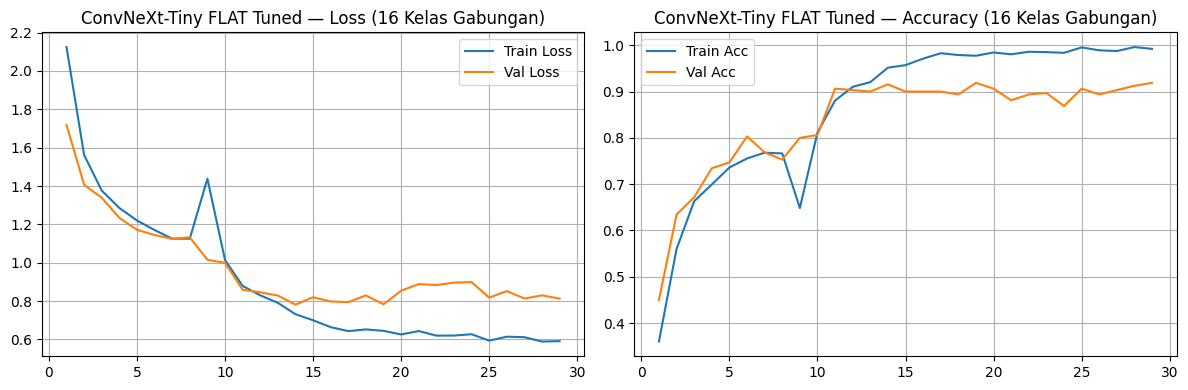


       TRAINING FLAT TUNED: FOLD 2 (100 EPOCHS)

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: 16 Kelas Gabungan
  MULAI TRAINING: FLAT Tuned Fold 2 | Output: 16 Kelas | Max Epoch: 100
FLAT Tuned Fold 2 | Epoch 01/100 | Train Loss: 2.1213 Acc: 36.09% | Val Loss: 1.6065 Acc: 60.62%
FLAT Tuned Fold 2 | Epoch 05/100 | Train Loss: 1.2217 Acc: 73.91% | Val Loss: 1.1791 Acc: 72.81%
FLAT Tuned Fold 2 | Epoch 10/100 | Train Loss: 1.0350 Acc: 80.94% | Val Loss: 0.9167 Acc: 85.31%
FLAT Tuned Fold 2 | Epoch 15/100 | Train Loss: 0.7086 Acc: 95.55% | Val Loss: 0.8368 Acc: 90.00%
FLAT Tuned Fold 2 | Epoch 20/100 | Train Loss: 0.6438 Acc: 97.73% | Val Loss: 0.8079 Acc: 91.25%
FLAT Tuned Fold 2 | Epoch 25/100 | Train Loss: 0.6001 Acc: 99.30% | Val Loss: 0.8729 Acc: 89.38%
[Early Stopping] FLAT Tuned Fold 2 berhenti di epoch 29.
=> FLAT Tuned Fold 2 Selesai! Best Val Accuracy: 94.06%


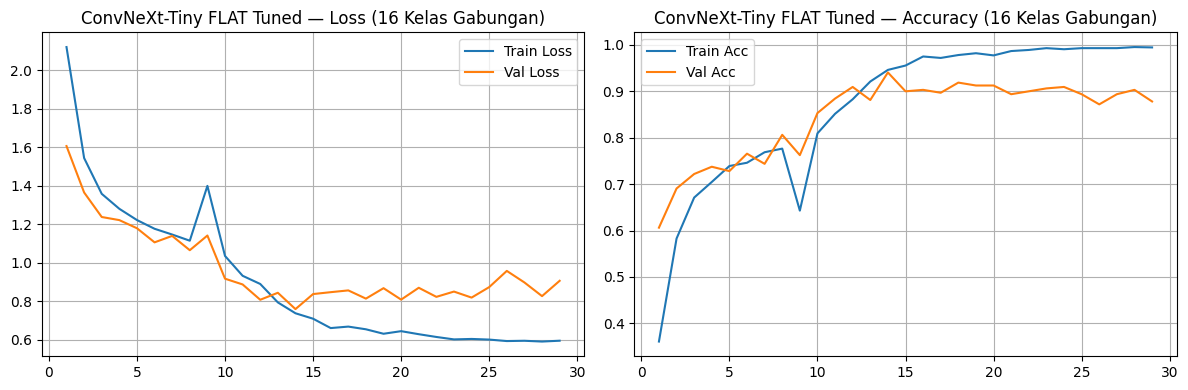


       TRAINING FLAT TUNED: FOLD 3 (100 EPOCHS)

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: 16 Kelas Gabungan
  MULAI TRAINING: FLAT Tuned Fold 3 | Output: 16 Kelas | Max Epoch: 100
FLAT Tuned Fold 3 | Epoch 01/100 | Train Loss: 2.1459 Acc: 33.91% | Val Loss: 1.7090 Acc: 55.00%
FLAT Tuned Fold 3 | Epoch 05/100 | Train Loss: 1.1990 Acc: 74.77% | Val Loss: 1.2441 Acc: 71.25%
FLAT Tuned Fold 3 | Epoch 10/100 | Train Loss: 0.9945 Acc: 82.81% | Val Loss: 0.9265 Acc: 85.31%
FLAT Tuned Fold 3 | Epoch 15/100 | Train Loss: 0.7119 Acc: 95.86% | Val Loss: 0.8201 Acc: 88.12%
FLAT Tuned Fold 3 | Epoch 20/100 | Train Loss: 0.6646 Acc: 97.81% | Val Loss: 0.8049 Acc: 90.62%
FLAT Tuned Fold 3 | Epoch 25/100 | Train Loss: 0.6060 Acc: 98.75% | Val Loss: 0.8381 Acc: 92.19%
FLAT Tuned Fold 3 | Epoch 30/100 | Train Loss: 0.5958 Acc: 99.30% | Val Loss: 0.8983 Acc: 88.75%
FLAT Tuned Fold 3 | Epoch 35/100 | Train Loss: 0.5973 Acc: 99.22% | Val Loss: 0.9004 Acc: 88.75%
[Early Stopping] FLAT Tuned Fol

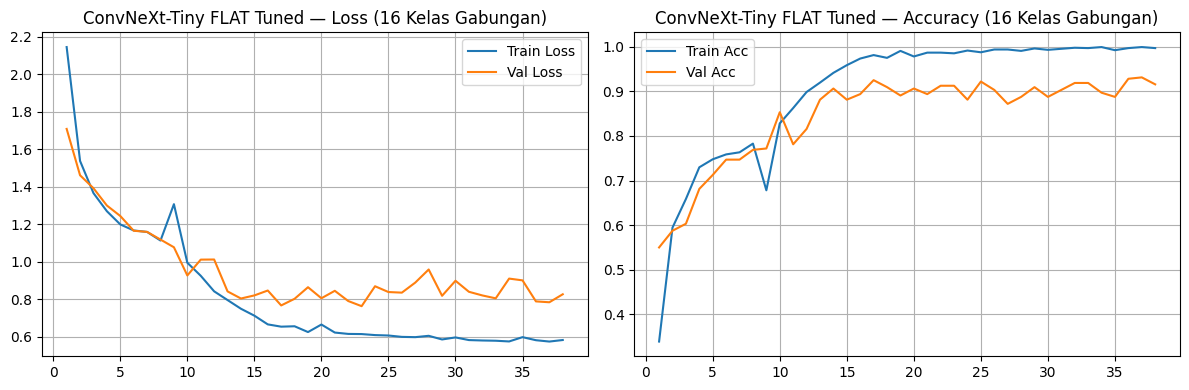


       TRAINING FLAT TUNED: FOLD 4 (100 EPOCHS)

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: 16 Kelas Gabungan
  MULAI TRAINING: FLAT Tuned Fold 4 | Output: 16 Kelas | Max Epoch: 100
FLAT Tuned Fold 4 | Epoch 01/100 | Train Loss: 2.1503 Acc: 35.55% | Val Loss: 1.7903 Acc: 41.25%
FLAT Tuned Fold 4 | Epoch 05/100 | Train Loss: 1.2092 Acc: 73.36% | Val Loss: 1.2720 Acc: 70.00%
FLAT Tuned Fold 4 | Epoch 10/100 | Train Loss: 0.9856 Acc: 83.20% | Val Loss: 0.9367 Acc: 86.56%
FLAT Tuned Fold 4 | Epoch 15/100 | Train Loss: 0.7056 Acc: 96.02% | Val Loss: 0.8381 Acc: 90.00%
FLAT Tuned Fold 4 | Epoch 20/100 | Train Loss: 0.6253 Acc: 98.83% | Val Loss: 0.8743 Acc: 88.75%
FLAT Tuned Fold 4 | Epoch 25/100 | Train Loss: 0.5919 Acc: 99.61% | Val Loss: 0.9150 Acc: 88.12%
FLAT Tuned Fold 4 | Epoch 30/100 | Train Loss: 0.5906 Acc: 99.38% | Val Loss: 0.8234 Acc: 90.94%
[Early Stopping] FLAT Tuned Fold 4 berhenti di epoch 34.
=> FLAT Tuned Fold 4 Selesai! Best Val Accuracy: 93.12%


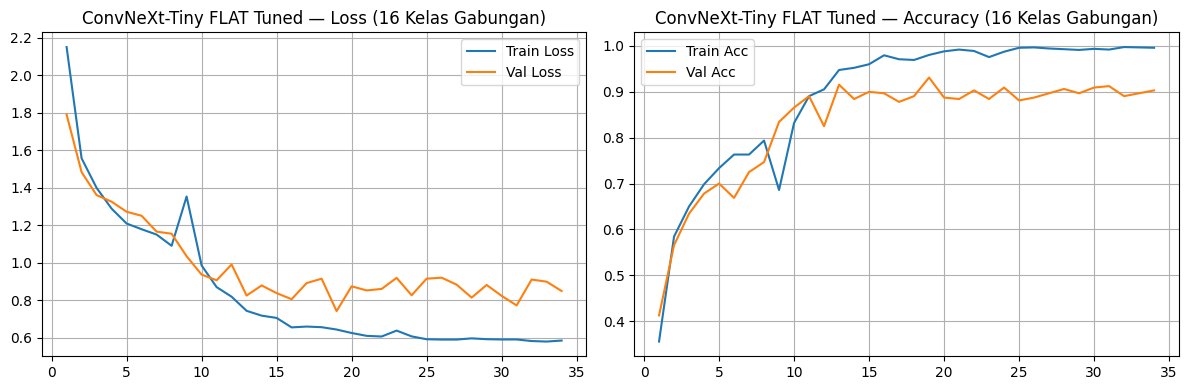


       TRAINING FLAT TUNED: FOLD 5 (100 EPOCHS)

[INFO] Device: cuda | Model: ConvNeXt-Tiny | Target: 16 Kelas Gabungan
  MULAI TRAINING: FLAT Tuned Fold 5 | Output: 16 Kelas | Max Epoch: 100
FLAT Tuned Fold 5 | Epoch 01/100 | Train Loss: 2.1314 Acc: 34.69% | Val Loss: 1.6567 Acc: 57.81%
FLAT Tuned Fold 5 | Epoch 05/100 | Train Loss: 1.2113 Acc: 73.52% | Val Loss: 1.2692 Acc: 67.19%
FLAT Tuned Fold 5 | Epoch 10/100 | Train Loss: 0.9724 Acc: 85.16% | Val Loss: 0.9361 Acc: 84.06%
FLAT Tuned Fold 5 | Epoch 15/100 | Train Loss: 0.7145 Acc: 94.92% | Val Loss: 0.8941 Acc: 87.50%
FLAT Tuned Fold 5 | Epoch 20/100 | Train Loss: 0.6201 Acc: 99.14% | Val Loss: 0.8352 Acc: 90.31%
FLAT Tuned Fold 5 | Epoch 25/100 | Train Loss: 0.6029 Acc: 99.30% | Val Loss: 0.8043 Acc: 92.19%
FLAT Tuned Fold 5 | Epoch 30/100 | Train Loss: 0.5865 Acc: 99.38% | Val Loss: 0.8097 Acc: 91.56%
[Early Stopping] FLAT Tuned Fold 5 berhenti di epoch 34.
=> FLAT Tuned Fold 5 Selesai! Best Val Accuracy: 92.81%


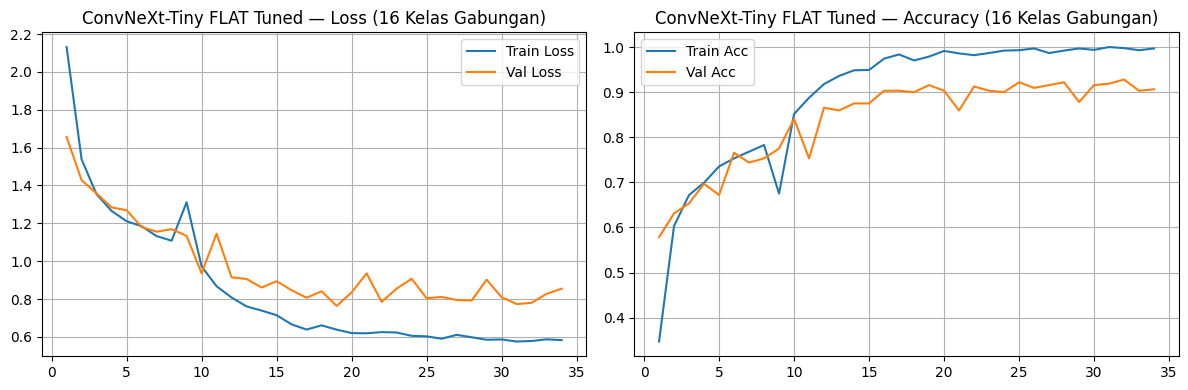


   REKAPITULASI STRATIFIED 5-FOLD: FLAT TUNED (100 EPOCHS)
  Fold  Accuracy (%)  Precision Macro (%)  Recall Macro (%)  F1 Macro (%)  F1 Weighted (%)
Fold 1         91.88                93.56             91.88         91.87            91.87
Fold 2         94.06                94.22             94.06         94.06            94.06
Fold 3         93.12                93.56             93.12         93.02            93.02
Fold 4         93.12                93.35             93.12         93.14            93.14
Fold 5         92.81                93.41             92.81         92.76            92.76
  MEAN         93.00                93.62             93.00         92.97            92.97
   STD          0.78                 0.35              0.78          0.79             0.79

[SAVED] Rekapitulasi CSV -> /kaggle/working/reports/KFold_Metrics_Summary_FLAT_Tuned_100Epochs.csv


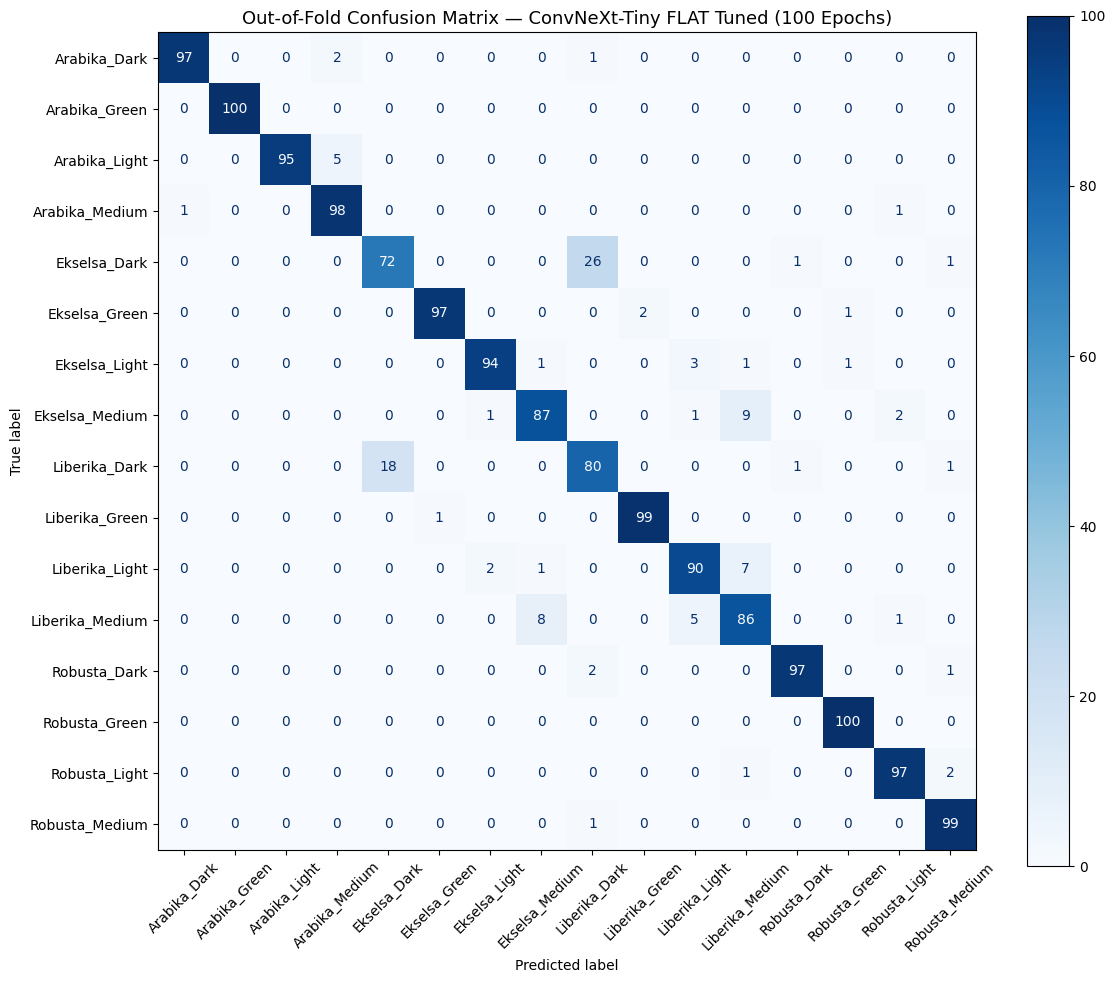

[SAVED] Confusion Matrix OOF -> /kaggle/working/reports/KFold_ConfusionMatrix_OOF_FLAT_Tuned.png
[SAVED] Confusion Matrix FLAT CSV -> /kaggle/working/reports/KFold_ConfusionMatrix_OOF_FLAT_Tuned.csv
[SAVED] Classification Report FLAT CSV -> /kaggle/working/reports/KFold_ClassificationReport_OOF_FLAT_Tuned.csv


In [5]:
train_tf, val_tf = get_transforms(img_size=224)
kfold_flat_metrics = []
oof_labels = []
oof_preds = []

for fold_num in range(1, 6):
    fold_train_path = os.path.join(TARGET_SPLIT2_DIR, f"fold_{fold_num}", "train")
    fold_val_path   = os.path.join(TARGET_SPLIT2_DIR, f"fold_{fold_num}", "val")

    print(f"\n{'='*65}")
    print(f"       TRAINING FLAT TUNED: FOLD {fold_num} (100 EPOCHS)")
    print(f"{'='*65}")

    train_ds = CoffeeDatasetFlatFolder(fold_train_path, transform=train_tf)
    val_ds   = CoffeeDatasetFlatFolder(fold_val_path,   transform=val_tf)

    train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=0)
    val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=0)

    model_save_path = f"{MODELS_DIR}/FLAT/ConvNeXt_FLAT_Fold{fold_num}.pth"

    # Latih fold FLAT dengan 100 epochs
    history, best_acc = train_kfold_model(
        train_loader  = train_loader,
        val_loader    = val_loader,
        num_classes   = 16,
        save_name     = model_save_path,
        label_info    = f"FLAT Tuned Fold {fold_num}",
        target_name   = "16 Kelas Gabungan",
        num_epochs    = 100,
        warmup_epochs = 8,
        patience      = 15
    )

    # Evaluasi Prediksi Fold untuk Out-of-Fold Matrix
    eval_model = build_convnext(num_classes=16).to(device)
    eval_model.load_state_dict(torch.load(model_save_path, map_location=device))
    eval_model.eval()

    fold_targets = []
    fold_predictions = []
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(device)
            outputs = eval_model(inputs)
            _, preds = torch.max(outputs, 1)
            fold_targets.extend(targets.cpu().numpy())
            fold_predictions.extend(preds.cpu().numpy())

    oof_labels.extend(fold_targets)
    oof_preds.extend(fold_predictions)

    f_acc = accuracy_score(fold_targets, fold_predictions) * 100
    f_p   = precision_score(fold_targets, fold_predictions, average='macro', zero_division=0) * 100
    f_r   = recall_score(fold_targets, fold_predictions, average='macro', zero_division=0) * 100
    f_f1  = f1_score(fold_targets, fold_predictions, average='macro', zero_division=0) * 100
    f_f1w = f1_score(fold_targets, fold_predictions, average='weighted', zero_division=0) * 100

    kfold_flat_metrics.append({
        'Fold': f"Fold {fold_num}",
        'Accuracy (%)': round(f_acc, 2),
        'Precision Macro (%)': round(f_p, 2),
        'Recall Macro (%)': round(f_r, 2),
        'F1 Macro (%)': round(f_f1, 2),
        'F1 Weighted (%)': round(f_f1w, 2)
    })

# --- TABEL REKAPITULASI 5-FOLD FLAT TUNED ---
df_flat_summary = pd.DataFrame(kfold_flat_metrics)
mean_row = {'Fold': 'MEAN'}
std_row  = {'Fold': 'STD'}

for col in ['Accuracy (%)', 'Precision Macro (%)', 'Recall Macro (%)', 'F1 Macro (%)', 'F1 Weighted (%)']:
    mean_row[col] = round(df_flat_summary[col].mean(), 2)
    std_row[col]  = round(df_flat_summary[col].std(), 2)

df_flat_final = pd.concat([df_flat_summary, pd.DataFrame([mean_row, std_row])], ignore_index=True)

print("\n" + "="*72)
print("   REKAPITULASI STRATIFIED 5-FOLD: FLAT TUNED (100 EPOCHS)")
print("="*72)
print(df_flat_final.to_string(index=False))
print("="*72)

# Simpan CSV ke reports/
flat_csv_path = f"{REPORTS_DIR}/KFold_Metrics_Summary_FLAT_Tuned_100Epochs.csv"
df_flat_final.to_csv(flat_csv_path, index=False)
print(f"\n[SAVED] Rekapitulasi CSV -> {flat_csv_path}")

# --- CONFUSION MATRIX OUT-OF-FOLD (1600 Citra) ---
cm_oof = confusion_matrix(oof_labels, oof_preds)
fig, ax = plt.subplots(figsize=(12, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_oof, display_labels=CLASS_NAMES_16)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45, values_format='d')
plt.title('Out-of-Fold Confusion Matrix — ConvNeXt-Tiny FLAT Tuned (100 Epochs)', fontsize=13)
plt.tight_layout()
cm_path = f"{REPORTS_DIR}/KFold_ConfusionMatrix_OOF_FLAT_Tuned.png"
plt.savefig(cm_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"[SAVED] Confusion Matrix OOF -> {cm_path}")

# --- SIMPAN CONFUSION MATRIX CSV & CLASSIFICATION REPORT CSV ---
df_cm_flat = pd.DataFrame(cm_oof, index=CLASS_NAMES_16, columns=CLASS_NAMES_16)
df_cm_flat.index.name = "True_Class"
cm_flat_csv = os.path.join(REPORTS_DIR, "KFold_ConfusionMatrix_OOF_FLAT_Tuned.csv")
df_cm_flat.to_csv(cm_flat_csv)
print(f"[SAVED] Confusion Matrix FLAT CSV -> {cm_flat_csv}")

report_flat = classification_report(oof_labels, oof_preds, target_names=CLASS_NAMES_16, output_dict=True)
df_rep_flat = pd.DataFrame(report_flat).T
df_rep_flat.index.name = "Class"
rep_flat_csv = os.path.join(REPORTS_DIR, "KFold_ClassificationReport_OOF_FLAT_Tuned.csv")
df_rep_flat.to_csv(rep_flat_csv, float_format="%.4f")
print(f"[SAVED] Classification Report FLAT CSV -> {rep_flat_csv}")

In [6]:
# --- EKSPOR ZIP HASIL TRAINING ---
import shutil
import tempfile

# Bersihkan folder dataset ekstraksi sementara di working dir jika ada agar disk lega
for item in os.listdir('/kaggle/working'):
    item_path = os.path.join('/kaggle/working', item)
    if os.path.isdir(item_path) and item not in ['models', 'reports']:
        shutil.rmtree(item_path, ignore_errors=True)

# Buat zip hanya untuk models (.pth) dan reports (PNG & CSV)
with tempfile.TemporaryDirectory() as tmp_dir:
    bundle_dir = os.path.join(tmp_dir, 'bundle')
    os.makedirs(bundle_dir, exist_ok=True)
    if os.path.exists(MODELS_DIR):
        shutil.copytree(MODELS_DIR, os.path.join(bundle_dir, 'models'), dirs_exist_ok=True)
    if os.path.exists(REPORTS_DIR):
        shutil.copytree(REPORTS_DIR, os.path.join(bundle_dir, 'reports'), dirs_exist_ok=True)
    
    output_zip = '/kaggle/working/Hasil_Training_FLAT_100Epochs'
    shutil.make_archive(output_zip, 'zip', bundle_dir)

print(f'\n[SUCCESS] Semua model (.pth) dan laporan grafik FLAT tersimpan di: /kaggle/working/Hasil_Training_FLAT_100Epochs.zip')


[SUCCESS] Semua model (.pth) dan laporan grafik FLAT tersimpan di: /kaggle/working/Hasil_Training_FLAT_100Epochs.zip
